In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dataco_Proje.csv", encoding="latin1")

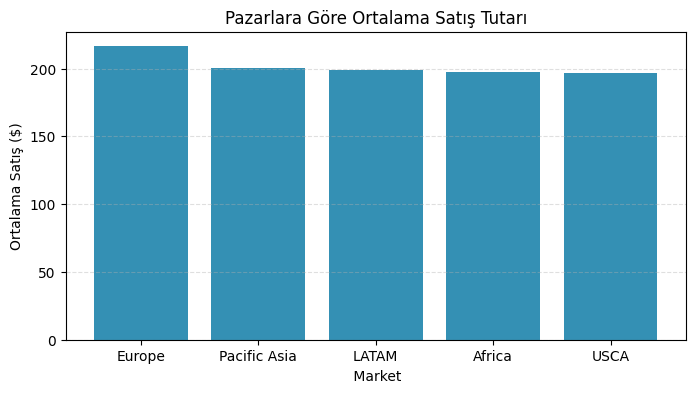

In [16]:
pazar_satis = df.groupby("Market")["Sales"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(pazar_satis.index, pazar_satis.values, color="#3490b4")
plt.title("Pazarlara Göre Ortalama Satış Tutarı")
plt.xlabel(" Market")
plt.ylabel("Ortalama Satış ($)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

## Market bazında ortalama satış tutarı

* Her bölgedeki ortalama satış tutarları birbirine oldukça yakın (yaklaşık 200$ bandında) seyretmektedir.
* En yüksek ortalama satış tutarı **Europe** pazarında gözlemlenirken, diğer pazarlarda (Pacific Asia, LATAM, Africa ve USCA) da benzer bir sepet ortalaması korunmaktadır.

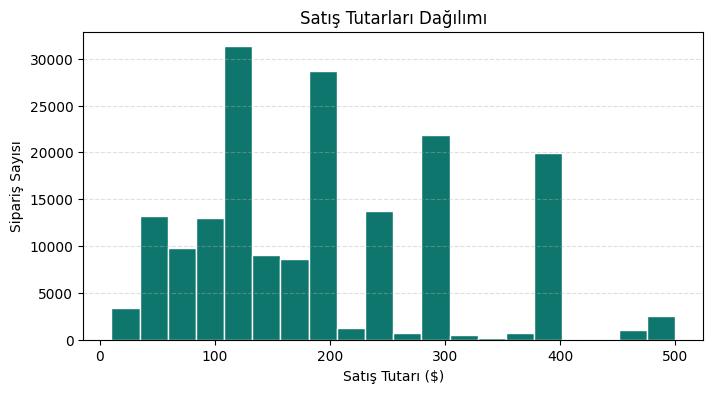

In [17]:
plt.figure(figsize=(8, 4))
plt.hist(df[df["Sales"] < 500]["Sales"].dropna(), bins=20, color="#0f766e", edgecolor="white")
plt.title("Satış Tutarları Dağılımı")
plt.xlabel("Satış Tutarı ($)")
plt.ylabel("Sipariş Sayısı")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

## Sipariş tutarlarının (Sales) dağılımı
* Siparişlerin 0-200 tutarları arasında daha fazla olduğunu görüyoruz.
* Bu grafikte uç değerleri baskıladık , çünkü grafiğimizin yapısını bozuyordu.

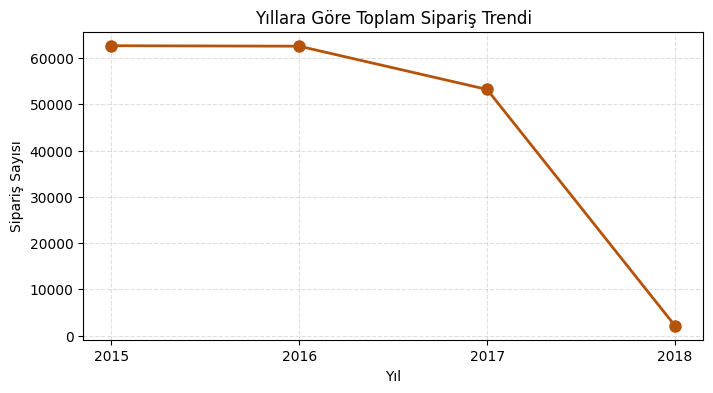

In [18]:
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"]) # string olan tarih sütunu , datetime formatina çevrildi burada.
yillik_siparis = df.groupby(df["order_date"].dt.year)["Order Id"].count()

plt.figure(figsize=(8, 4))
plt.plot(yillik_siparis.index.astype(str), yillik_siparis.values, color="#b45309", marker="o", markersize=8, linewidth=2)
plt.title("Yıllara Göre Toplam Sipariş Trendi")
plt.xlabel("Yıl")
plt.ylabel("Sipariş Sayısı")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

##  Yıllara göre toplam sipariş adedi

* 2015 YILINDAN itibaren gözle görülür bir şekilde , her yıl  sipariş sayısında azalmanın meydana geldiğini söyleyebiliriz.


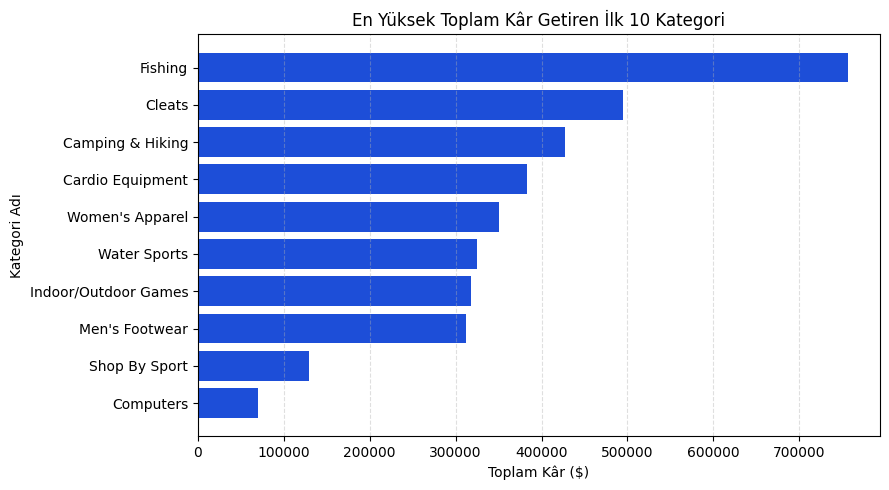

In [19]:
top10_kar = df.groupby("Category Name")["Order Profit Per Order"].sum().sort_values(ascending=True).tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top10_kar.index, top10_kar.values, color="#1d4ed8")
plt.title("En Yüksek Toplam Kâr Getiren İlk 10 Kategori")
plt.xlabel("Toplam Kâr ($)")
plt.ylabel("Kategori Adı")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Özet Olarak : Kategori Bazlı Kârlılık Analizi
* Şirketin toplam kârının büyük bölümü belirli lokomotif ürün kategorilerinde (örneğin *Fishing*, *Cleats*, *Camping & Hiking* gibi) yoğunlaşmaktadır.
* Pazarlama ve stok bütçesinin bu ilk 10 kategoriye odaklanması, kârlılık marjını korumak açısından kritik öneme sahiptir.

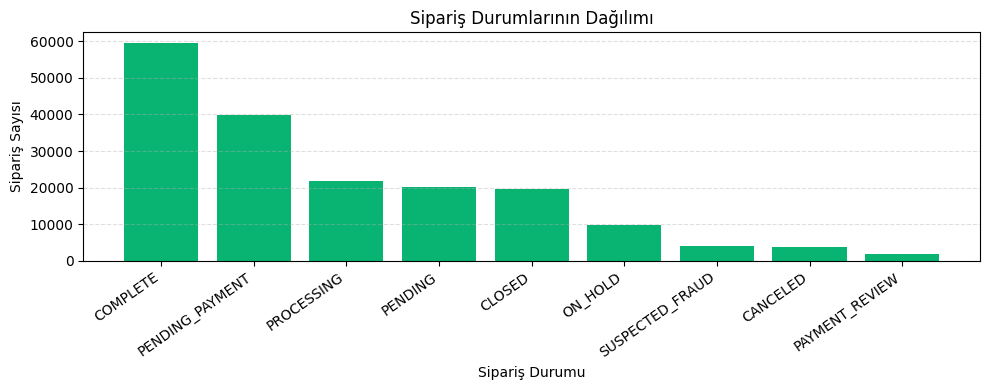

In [20]:
siparis_durum = df["Order Status"].value_counts()

plt.figure(figsize=(10, 4))
plt.bar(siparis_durum.index, siparis_durum.values, color="#09b472")
plt.title("Sipariş Durumlarının Dağılımı")
plt.xlabel("Sipariş Durumu")
plt.ylabel("Sipariş Sayısı")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Özetle: Sipariş Durumları ve Risk Görünümü
* Siparişlerin büyük çoğunluğu "COMPLETE" ve "PENDING_PAYMENT" statüsünde yer alırken, "CANCELED" ve "SUSPECTED_FRAUD" statülerinin toplam hacim içindeki payı dikkat çekmektedir.
* Şüpheli işlem ("SUSPECTED_FRAUD") oranının yüksek olduğu pazar veya ödeme türlerinin alt kırılımda incelenmesi gelir kaybını azaltacaktır.

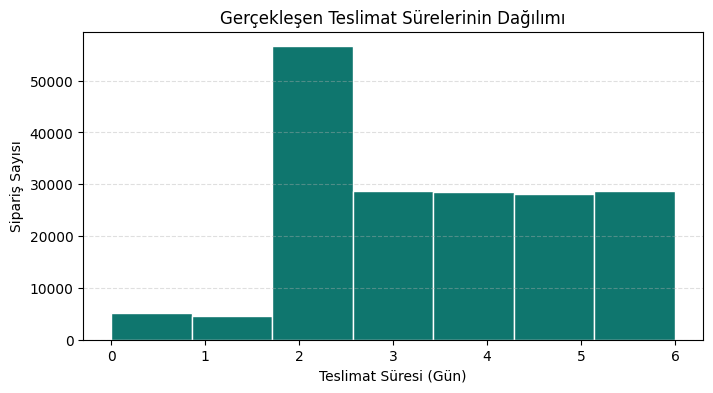

In [21]:
plt.figure(figsize=(8, 4))
plt.hist(df["Days for shipping (real)"], bins=7, color="#0f766e", edgecolor="white")
plt.title("Gerçekleşen Teslimat Sürelerinin Dağılımı")
plt.xlabel("Teslimat Süresi (Gün)")
plt.ylabel("Sipariş Sayısı")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

###  Özet: Teslimat Süreleri Dağılımı
* Siparişlerin teslimat sürelerinin ağırlıklı olarak 2 ile 6 gün arasında yoğunlaştığı görülmektedir.
* Dağılımın tek bir günde yığılmak yerine 2-6 gün bandına yayılması, farklı kargo modlarının (Same Day, First Class, Standard Class) bir arada bulunmasından kaynaklanmaktadır.

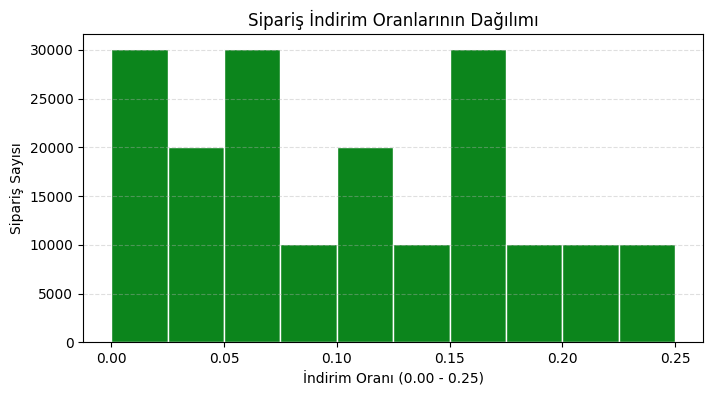

In [23]:
plt.figure(figsize=(8, 4))
plt.hist(df["Order Item Discount Rate"], bins=10, color="#0c851c", edgecolor="white")
plt.title("Sipariş İndirim Oranlarının Dağılımı")
plt.xlabel("İndirim Oranı (0.00 - 0.25)")
plt.ylabel("Sipariş Sayısı")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

###  Özet: İndirim Oranları Dağılımı
* İndirim oranlarının %0 ile %25 (`0.00` - `0.25`) aralığında belirli basamaklarda yoğunlaştığı görülmektedir.
* Şirketin rastgele indirimler yerine standart kampanya kademeleri (örneğin %5, %10, %15, %20) uyguladığı anlaşılmaktadır.